# MODIS land-cover EDA

Explore validated, discovered development-period MCD12Q1 v6.1 maps on the native categorical grid. Missing nominal years stay missing. This notebook defaults to the expanded profile and excludes held-out years. Same-year retrospective assignment and explicit carry-forward are different policies; neither proves historical publication availability.


In [1]:
import os
import json
from peatguard.study import find_root, load_study
from peatguard.spatial import validated_maps, select_maps
ROOT = find_root()
STUDY = load_study(root=ROOT, profile="expanded", as_of=os.getenv("PEATGUARD_AS_OF"))

import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd
from pyproj import Transformer
import rasterio
from rasterio.features import geometry_mask
import shapely
from shapely.geometry import mapping, shape
from shapely.ops import transform as transform_geom
from shapely.plotting import plot_polygon

## Available source files: training and 2025 test

The table includes test-year file availability. The plots below still use training dates only. File presence and recorded source coverage do not establish complete model-label coverage.

In [2]:
source_manifest = json.loads((ROOT / STUDY.config["sources"]["modis"]["directory"] / "manifest.json").read_text())
source_availability = pd.DataFrame([
    {"year": item["year"], "role": role,
     "file_present": (ROOT / item["file"]).is_file(),
     "recorded_days": item.get("days", "annual map"), "file": item["file"]}
    for item in source_manifest["years"]
    for role, (start, end) in STUDY.profile_config["splits"].items()
    if int(start[:4]) <= int(item["year"]) <= int(end[:4])
]).sort_values(["year", "role"]).reset_index(drop=True)
print("2025 is registered as TEST data; training summaries below stop at 2024.")
display(source_availability)


2025 is registered as TEST data; training summaries below stop at 2024.


,year,role,file_present,recorded_days,file
0,2020,train,True,annual map,data/interim/modis_landcover/modis_mcd12q1_061...
1,2021,train,True,annual map,data/interim/modis_landcover/modis_mcd12q1_061...
2,2022,train,True,annual map,data/interim/modis_landcover/modis_mcd12q1_061...
3,2023,train,True,annual map,data/interim/modis_landcover/modis_mcd12q1_061...
4,2024,train,True,annual map,data/interim/modis_landcover/modis_mcd12q1_061...
5,2025,test,True,annual map,data/interim/modis_landcover/.partitions/modis...


## 1. Read annual maps and verify their shared native grid

Each file has three integer bands: IGBP `LC_Type1` classes 1–17, `QC` codes 0–9, and `LW` (1 water, 2 land). QC **0 means classified land**, so zero is not a missing-value code. The saved GeoTIFFs therefore have no nodata value.

In [3]:
data_dir = ROOT / "data/interim/modis_landcover"
manifest = json.loads((data_dir / "manifest.json").read_text())
annual = {}
available = validated_maps(STUDY)
development_years = {day.year for day in STUDY.development_dates()}
paths = {year: path for year, path in available.items() if year in development_years}
print("Strict same-year assignment:", select_maps(STUDY))
print("Missing development map years:", sorted(development_years - paths.keys()))
if not paths:
    raise ValueError("No validated development maps available; acquire published maps first.")
for year, path in sorted(paths.items()):
    with rasterio.open(path) as source:
        assert source.descriptions == ("LC_Type1", "QC", "LW")
        assert source.nodata is None
        if not annual:
            crs, affine = source.crs, source.transform
            height, width = source.height, source.width
        else:
            assert source.crs == crs
            assert np.allclose(tuple(source.transform)[:6], tuple(affine)[:6], rtol=0, atol=1e-4)  # absolute 0.1 mm serialization tolerance
            assert (source.height, source.width) == (height, width)
        annual[year] = source.read()
print("Source:", manifest.get("source", "MODIS MCD12Q1 v6.1"))
print("Native grid:", width, "columns ×", height, "rows")
print("Pixel size:", round(abs(affine.a), 2), "m ×", round(abs(affine.e), 2), "m")
print("Years:", list(annual))
print("Bands:", STUDY.config["sources"]["modis"]["bands"])
print("CRS:", crs.to_proj4())
years = sorted(annual)
first_year, latest_year = years[0], years[-1]


Strict same-year assignment: [{'data_year': 2020, 'map_year': 2020, 'policy': 'strict_same_year', 'status': 'ready', 'staleness_years': 0, 'path': 'data/interim/modis_landcover/modis_mcd12q1_061_kalimantan_2020.tif', 'historical_release_evidence': 'unknown', 'forecast_availability_proven': False}, {'data_year': 2021, 'map_year': 2021, 'policy': 'strict_same_year', 'status': 'ready', 'staleness_years': 0, 'path': 'data/interim/modis_landcover/modis_mcd12q1_061_kalimantan_2021.tif', 'historical_release_evidence': 'unknown', 'forecast_availability_proven': False}, {'data_year': 2022, 'map_year': 2022, 'policy': 'strict_same_year', 'status': 'ready', 'staleness_years': 0, 'path': 'data/interim/modis_landcover/modis_mcd12q1_061_kalimantan_2022.tif', 'historical_release_evidence': 'unknown', 'forecast_availability_proven': False}, {'data_year': 2023, 'map_year': 2023, 'policy': 'strict_same_year', 'status': 'ready', 'staleness_years': 0, 'path': 'data/interim/modis_landcover/modis_mcd12q1_06

## 2. Define the five-province study mask

The download is a rectangle containing sea and territory outside the study. Rasterizing BIG's provincial polygons on the MODIS grid includes a pixel when its **center** falls inside a province. This is a descriptive mask, not the eventual peatland mask.

In [4]:
with (ROOT / STUDY.config["boundaries"]["provinces"]).open(encoding="utf-8") as file:
    province_geojson = json.load(file)

def keep_xy(coordinates):
    if isinstance(coordinates[0], (int, float)):
        return coordinates[:2]
    return [keep_xy(part) for part in coordinates]

transformer = Transformer.from_crs("EPSG:4326", crs, always_xy=True)
provinces = [(feature["properties"]["WADMPR"], transform_geom(
    transformer.transform,
    shape({"type": feature["geometry"]["type"],
           "coordinates": keep_xy(feature["geometry"]["coordinates"])})
)) for feature in province_geojson["features"]]
province_union = shapely.union_all([geom for _, geom in provinces])
province_mask = geometry_mask([mapping(province_union)], out_shape=(height, width),
                              transform=affine, invert=True, all_touched=False)
pixel_area_km2 = abs(affine.a * affine.e) / 1_000_000
print(f"Native pixels with centers in five provinces: {province_mask.sum():,}")
print(f"Pixel area: {pixel_area_km2:.4f} km²; center-mask area: {province_mask.sum()*pixel_area_km2:,.0f} km²")

Native pixels with centers in five provinces: 2,502,005
Pixel area: 0.2147 km²; center-mask area: 537,077 km²


## 3. Class and quality-code checks

IGBP labels are **categories**, not ordered numbers. Class 17 is water. QC 0 is classified land and QC 2 is classified water; other codes record missing classifications or corrections. We examine all codes before deciding which labels to keep for modeling.

In [5]:
IGBP = {
    1: "Evergreen needleleaf forest", 2: "Evergreen broadleaf forest",
    3: "Deciduous needleleaf forest", 4: "Deciduous broadleaf forest",
    5: "Mixed forest", 6: "Closed shrublands", 7: "Open shrublands",
    8: "Woody savannas", 9: "Savannas", 10: "Grasslands",
    11: "Permanent wetlands", 12: "Croplands", 13: "Urban/built-up",
    14: "Cropland/natural vegetation mosaic", 15: "Snow/ice",
    16: "Barren/sparsely vegetated", 17: "Water",
}
PALETTE = [
    "#05450a", "#086a10", "#54a708", "#78d203", "#009900",
    "#c6b044", "#dcd159", "#dade48", "#fbff13", "#b6ff05",
    "#27ff87", "#c24f44", "#a5a5a5", "#ff6d4c", "#69fff8",
    "#f9ffa4", "#1c0dff",
]
QC = {
    0: "Classified land", 1: "Unclassified land", 2: "Classified water",
    3: "Unclassified water", 4: "Classified sea ice (catalog wording)", 5: "Corrected water label",
    6: "Corrected snow/ice label", 7: "Corrected snow/ice label",
    8: "Backfilled label", 9: "Forest type changed",
}
quality_rows = []
class_rows = []
for year, cube in annual.items():
    classes, qc, land_water = cube
    selected_class = classes[province_mask]
    selected_qc = qc[province_mask]
    selected_lw = land_water[province_mask]
    assert np.isin(selected_class, range(1, 18)).all()
    assert np.isin(selected_qc, range(10)).all()
    assert np.isin(selected_lw, [1, 2]).all()
    land = selected_class != 17
    quality_rows.append({
        "year": year,
        "province_pixels": len(selected_class),
        "water_class_pct": 100 * np.mean(~land),
        "qc_classified_land_pct_of_land": 100 * np.mean(selected_qc[land] == 0),
        "qc_unclassified_land_pixels": int(np.sum(selected_qc == 1)),
        "class_vs_lw_disagreement_pixels": int(np.sum((selected_class == 17) != (selected_lw == 1))),
    })
    codes, counts = np.unique(selected_class, return_counts=True)
    for code, count in zip(codes, counts):
        class_rows.append({"year": year, "class_code": int(code),
                           "class_name": IGBP[int(code)], "pixels": int(count),
                           "area_km2": count * pixel_area_km2})
quality = pd.DataFrame(quality_rows).set_index("year")
class_counts = pd.DataFrame(class_rows)
print(quality.round(2).to_string())

      province_pixels  water_class_pct  qc_classified_land_pct_of_land  qc_unclassified_land_pixels  class_vs_lw_disagreement_pixels
year                                                                                                                                
2020          2502005             0.54                           99.50                         2941                              139
2021          2502005             0.55                           99.47                         3394                              168
2022          2502005             0.55                           99.42                         4347                              299
2023          2502005             0.55                           99.39                         3560                              355
2024          2502005             0.55                           99.36                         3543                              362


In [6]:
qc_latest = annual[latest_year][1][province_mask]
qc_codes, qc_counts = np.unique(qc_latest, return_counts=True)
qc_table = pd.DataFrame({"code": qc_codes, "description": [QC[int(code)] for code in qc_codes],
                         "pixels": qc_counts,
                         "pct_of_province": 100 * qc_counts / province_mask.sum()})
qc_table.round(2)

,code,description,pixels,pct_of_province
0,0,Classified land,2472550,98.82
1,1,Unclassified land,3543,0.14
2,2,Classified water,4028,0.16
3,3,Unclassified water,30,0.00
4,4,Classified sea ice (catalog wording),9461,0.38
5,5,Corrected water label,637,0.03
6,8,Backfilled label,8930,0.36
7,9,Forest type changed,2826,0.11


The catalog calls QC code 4 “classified sea ice,” yet every such pixel inside our tropical study mask has the IGBP water label (17). We do not interpret this as physical sea ice. Some other QC descriptions also appear inconsistent with the local class (for example, code 9 with urban). Treat these as source codes to investigate, not direct ecological labels or an automatic filter.

## 4. Land-cover composition by year

This chart excludes class 17 water and uses **native-pixel counts**, not one-hot encoded model inputs. The percentages are approximate area shares because native MODIS sinusoidal pixels have equal area; pixel-center masking makes the provincial edge approximate.

In [7]:
land_counts = class_counts[class_counts.class_code != 17].copy()
land_counts["share_of_land_pct"] = land_counts.groupby("year")["pixels"].transform(lambda x: 100*x/x.sum())
share_table = land_counts.pivot(index="class_name", columns="year", values="share_of_land_pct").fillna(0)
share_table.sort_values(latest_year, ascending=False).round(2).head(12)

year,2020,2021,2022,2023,2024
class_name,,,,,
Evergreen broadleaf forest,67.98,68.32,69.23,69.69,70.25
Woody savannas,23.17,22.93,22.12,21.46,21.11
Savannas,3.29,3.10,2.81,3.07,3.18
Permanent wetlands,2.31,2.36,2.40,2.33,2.31
Grasslands,2.11,2.03,2.05,2.11,1.87
Cropland/natural vegetation mosaic,0.81,0.96,1.10,1.01,0.98
Urban/built-up,0.18,0.18,0.18,0.18,0.19
Croplands,0.13,0.12,0.10,0.11,0.10
Closed shrublands,0.02,0.02,0.02,0.02,0.01


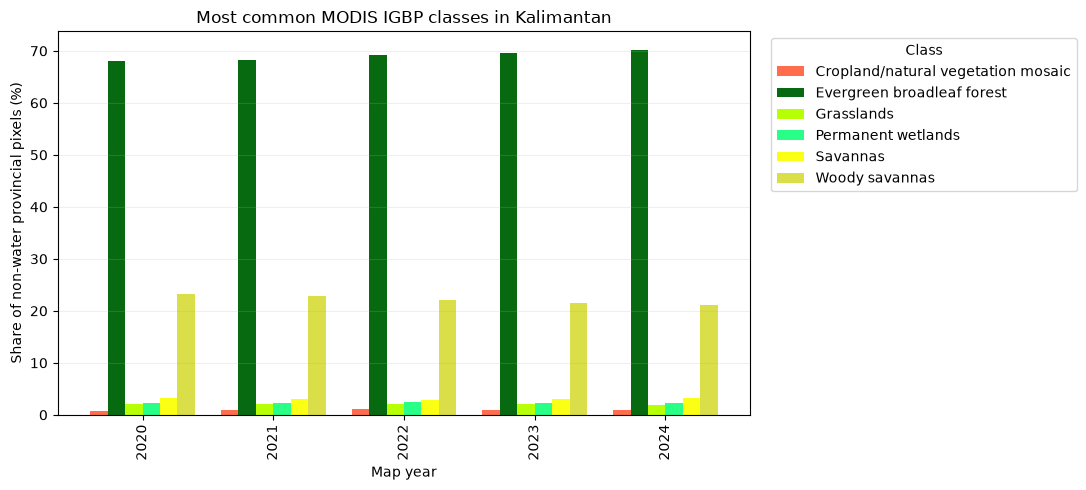

In [8]:
top_codes = (land_counts[land_counts.year == latest_year].nlargest(6, "pixels").class_code.tolist())
plot_data = land_counts[land_counts.class_code.isin(top_codes)].pivot(
    index="year", columns="class_name", values="share_of_land_pct").fillna(0)
name_to_code = {name: code for code, name in IGBP.items()}
colors = [PALETTE[name_to_code[name]-1] for name in plot_data.columns]
ax = plot_data.plot(kind="bar", figsize=(11, 5), width=0.8, color=colors)
ax.set(title="Most common MODIS IGBP classes in Kalimantan", xlabel="Map year",
       ylabel="Share of non-water provincial pixels (%)")
ax.legend(title="Class", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout(); plt.show()

## 5. Native-grid maps and apparent change

The same class colors appear in both years. Annual map differences can reflect actual land-cover change **and** classification uncertainty. The product's annual map may only become available after its nominal year, so using the same-year map in a forward forecast requires a timing check.

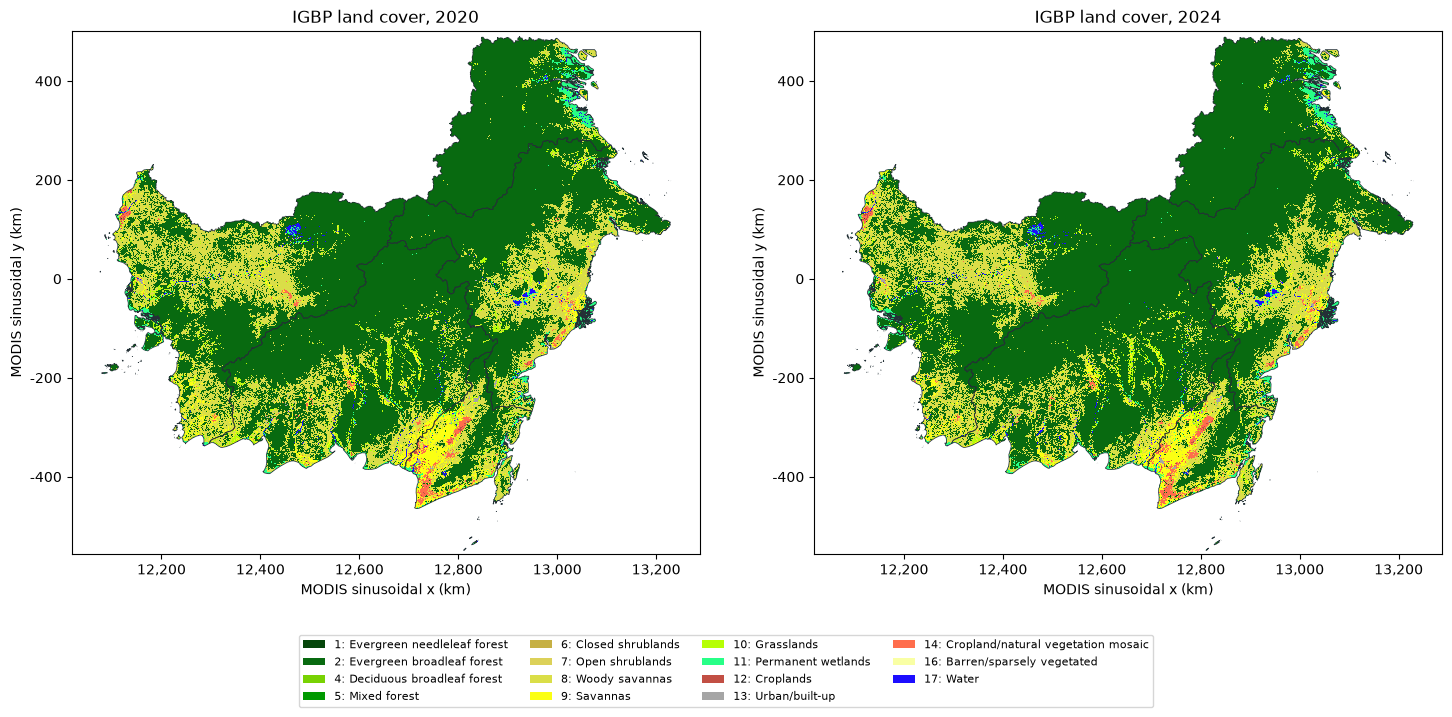

In [9]:
cmap = ListedColormap(PALETTE)
cmap.set_bad("white")
norm = BoundaryNorm(np.arange(0.5, 18.5), cmap.N)
west, north = affine * (0, 0)
east, south = affine * (width, height)
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for ax, year in zip(axes, [first_year, latest_year]):
    classes = np.ma.masked_where(~province_mask, annual[year][0])
    ax.imshow(classes, cmap=cmap, norm=norm, origin="upper", interpolation="nearest",
              extent=[west, east, south, north])
    for _, geom in provinces:
        plot_polygon(geom.simplify(500, preserve_topology=True), ax=ax,
                     add_points=False, facecolor="none", edgecolor="#243036", linewidth=0.55)
    ax.set(title=f"IGBP land cover, {year}", xlabel="MODIS sinusoidal x (km)",
           ylabel="MODIS sinusoidal y (km)")
    ax.set_aspect("equal", adjustable="box")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value/1000:,.0f}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value/1000:,.0f}"))
observed = sorted(set(np.unique(annual[first_year][0][province_mask])) |
                  set(np.unique(annual[latest_year][0][province_mask])))
handles = [Patch(facecolor=PALETTE[code-1], label=f"{code}: {IGBP[code]}") for code in observed]
fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=8, bbox_to_anchor=(0.5, 0.005))
fig.tight_layout(rect=(0, 0.21, 1, 1))
plt.show()

In [10]:
change_rows = []
for earlier, later in zip(years[:-1], years[1:]):
    if later != earlier + 1:
        print(f"No annual-change estimate across missing maps: {earlier} to {later}")
        continue
    before, after = annual[earlier][0], annual[later][0]
    comparable = province_mask & (before != 17) & (after != 17)
    change_rows.append({"period": f"{earlier}→{later}",
                        "comparable_land_pixels": int(comparable.sum()),
                        "different_class_pct": 100 * np.mean(before[comparable] != after[comparable])})
change = pd.DataFrame(change_rows, columns=["period", "comparable_land_pixels", "different_class_pct"]).set_index("period")
change.round(2)

,comparable_land_pixels,different_class_pct
period,,
2020→2021,2488334,4.56
2021→2022,2488191,4.46
2022→2023,2488097,4.76
2023→2024,2488072,4.91


## Interpretation before preprocessing

- The paper's “Collection 6” reference does not establish whether it used Version 6.0 or 6.1, which annual map, or which MCD12Q1 classification scheme. Our `LC_Type1` choice is documented and revisable.
- Keep class labels categorical. For the final 5 × 5 km grid, decide how to summarize many 500 m pixels (for example, dominant class or class proportions), then encode classes without imposing a numeric order.
- Choose a land-cover map known by the prediction date. A same-year annual classification can contain information from later in that year; treat its availability as a potential leakage issue.
- Exclude water and scrutinize QC codes when defining modeling cells. The map is not a peatland boundary.